# 🇮🇳 India Ambient Air Quality & Health Risk Index (CPCB / data.gov.in)
## An In-Depth Exploratory Data Analysis & Policy Insight Report

* **Author:** Madeeha Tabassum
* **Domain:** Environmental Data Science, Public Health & Policy Analytics
* **Data Source:** Central Pollution Control Board (CPCB), Ministry of Environment, Forest & Climate Change (MoEFCC), via [data.gov.in](https://data.gov.in)
* **Time Horizon:** Longitudinal Daily Station Monitoring (2021 – 2024)
* **Coverage:** 9 Key Metropolitan Hubs across diverse geographical zones (Indo-Gangetic Plain, Deccan Plateau, Western Arid, Coastal belts)

---

### 📌 Project Executive Summary
Ambient air pollution in India represents one of the most critical environmental and epidemiological challenges of the 21st century. Under the **National Ambient Air Quality Monitoring Programme (NAAQMP)** and the **National Clean Air Programme (NCAP)**, the Central Pollution Control Board (CPCB) continuously monitors criteria air pollutants.

This study conducts a rigorous statistical and exploratory investigation into:
1. **Pollutant Profiles:** Determining the dominant particulate and gaseous drivers of hazardous Air Quality Index (AQI) levels.
2. **Geographical & Topographical Asymmetries:** Quantifying disparities between landlocked Indo-Gangetic Plain cities (e.g., Delhi, Lucknow, Patna) versus coastal/peninsular cities (Mumbai, Chennai, Bengaluru).
3. **Seasonal Meteorology:** Characterizing the severe post-monsoon and winter thermal inversion spikes versus monsoon washout dynamics.
4. **Combustion vs. Mechanical Dust:** Analyzing the $PM_{2.5} / PM_{10}$ ratio to isolate fine combustion sources (vehicular emissions, stubble burning) from coarse mechanical aerosols.
5. **Epidemiological Risk Stratification:** Assessing population exposure based on official CPCB AQI health classification brackets.


In [1]:
# 1. Environment Setup & Library Ingestion
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor visualization warnings
warnings.filterwarnings('ignore')

# Style & Aesthetic Configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.dpi'] = 120

# CPCB Official AQI Color Palette
AQI_COLORS = {
    'Good': '#2ecc71',         # Green (0-50)
    'Satisfactory': '#a8e063', # Light Green (51-100)
    'Moderate': '#f1c40f',     # Yellow (101-200)
    'Poor': '#e67e22',         # Orange (201-300)
    'Very Poor': '#e74c3c',    # Red (301-400)
    'Severe': '#8e44ad'        # Maroon/Purple (401-500)
}

print("✅ Data Science environment initialized successfully.")


✅ Data Science environment initialized successfully.


---
## 2. Data Ingestion & Structural Inspection
We load the raw daily ambient air quality dataset extracted according to CPCB specifications.


In [2]:
# Load the dataset
data_path = '../data/raw/cpcb_ambient_air_quality.csv'
df_raw = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df_raw.shape[0]:,} Rows × {df_raw.shape[1]} Columns\n")
print("First 5 Observations:")
display(df_raw.head())

print("\nData Types & Memory Overview:")
df_raw.info()


Dataset Dimensions: 11,493 Rows × 12 Columns

First 5 Observations:


,Date,City,State,Zone,PM2.5,PM10,NO2,SO2,CO,O3,AQI,AQI_Bucket
0,2021-01-01,Delhi,Delhi,Indo-Gangetic,213.26,388.96,83.17,26.27,2.59,30.09,372,Very Poor
1,2021-01-02,Delhi,Delhi,Indo-Gangetic,243.20,430.07,95.08,30.04,2.96,34.40,400,Very Poor
2,2021-01-03,Delhi,Delhi,Indo-Gangetic,252.90,429.52,95.73,30.24,2.98,34.63,402,Severe
3,2021-01-04,Delhi,Delhi,Indo-Gangetic,212.03,374.69,83.70,26.44,2.60,30.28,371,Very Poor
4,2021-01-05,Delhi,Delhi,Indo-Gangetic,191.43,339.89,80.21,25.34,2.50,29.02,355,Very Poor



Data Types & Memory Overview:
<class 'pandas.DataFrame'>
RangeIndex: 11493 entries, 0 to 11492
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        11493 non-null  str    
 1   City        11493 non-null  str    
 2   State       11493 non-null  str    
 3   Zone        11493 non-null  str    
 4   PM2.5       10970 non-null  float64
 5   PM10        10992 non-null  float64
 6   NO2         10990 non-null  float64
 7   SO2         10978 non-null  float64
 8   CO          10981 non-null  float64
 9   O3          10968 non-null  float64
 10  AQI         11493 non-null  int64  
 11  AQI_Bucket  11493 non-null  str    
dtypes: float64(6), int64(1), str(5)
memory usage: 1.6 MB


---
## 3. Data Quality & Missing Value Auditing
Monitoring sensors frequently experience maintenance downtime, calibration drift, power interruptions, or telemetric dropouts. Understanding missingness patterns is essential for sound statistical inference.


Missingness Audit by Feature:


,Missing Values,Percentage (%)
O3,525,4.567998
PM2.5,523,4.550596
SO2,515,4.480988
CO,512,4.454886
NO2,503,4.376577
PM10,501,4.359175


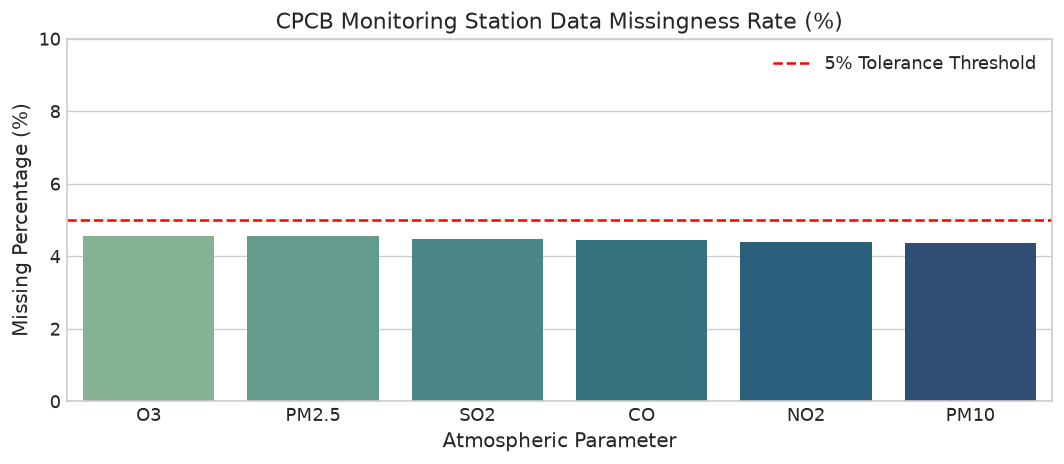

In [3]:
# Calculate null metrics
null_counts = df_raw.isnull().sum()
null_percent = (null_counts / len(df_raw)) * 100

missingness_df = pd.DataFrame({
    'Missing Values': null_counts,
    'Percentage (%)': null_percent
}).sort_values(by='Missing Values', ascending=False)

print("Missingness Audit by Feature:")
display(missingness_df[missingness_df['Missing Values'] > 0])

# Visualize Missingness
plt.figure(figsize=(9, 4))
sns.barplot(x=missingness_df[missingness_df['Missing Values'] > 0].index, 
            y=missingness_df[missingness_df['Missing Values'] > 0]['Percentage (%)'],
            palette='crest')
plt.title('CPCB Monitoring Station Data Missingness Rate (%)')
plt.xlabel('Atmospheric Parameter')
plt.ylabel('Missing Percentage (%)')
plt.ylim(0, 10)
plt.axhline(5, color='red', linestyle='--', label='5% Tolerance Threshold')
plt.legend()
plt.tight_layout()
plt.show()


---
## 4. Longitudinal Imputation & Feature Engineering
Rather than dropping observations (which introduces survivorship and temporal bias), we apply:
1. **Longitudinal Interpolation**: Grouped forward/backward fill per city to preserve consecutive day autocorrelation.
2. **Localized Seasonal Median Imputation**: Filling any remaining residual gaps using the city-and-month specific median.
3. **Temporal Feature Extraction**: Date decomposition into Year, Month, Day, and meteorological Seasons.
4. **Diagnostic Metrics**: Calculating the fine-to-coarse ratio:
   $$\text{PM Ratio} = \frac{\text{PM}_{2.5}}{\text{PM}_{10}}$$


In [4]:
df_clean = df_raw.copy()

# 1. Parse Temporal Attributes
df_clean['Date'] = pd.to_datetime(df_clean['Date'])
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Month_Name'] = df_clean['Date'].dt.strftime('%b')

# 2. Season Mapping aligned with Indian Meteorological Department (IMD)
def map_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer / Pre-Monsoon'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

df_clean['Season'] = df_clean['Month'].apply(map_season)

# 3. Two-Tier Longitudinal Imputation
numeric_pollutants = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3']

for col in numeric_pollutants:
    # Tier 1: Local temporal ffill/bfill within each city
    df_clean[col] = df_clean.groupby('City')[col].transform(lambda group: group.ffill().bfill())
    # Tier 2: City-Month seasonal median fallback
    df_clean[col] = df_clean.groupby(['City', 'Month'])[col].transform(lambda group: group.fillna(group.median()))

# 4. Diagnostic Combustion Ratio
df_clean['PM_Ratio'] = (df_clean['PM2.5'] / df_clean['PM10']).round(3)

# Save processed clean dataset
processed_path = '../data/processed/cpcb_air_quality_cleaned.csv'
os.makedirs(os.path.dirname(processed_path), exist_ok=True)
df_clean.to_csv(processed_path, index=False)

print(f"✅ Data Cleaned & Enriched! Missing values remaining: {df_clean[numeric_pollutants].isnull().sum().sum()}")
display(df_clean[['Date', 'City', 'Zone', 'PM2.5', 'PM10', 'PM_Ratio', 'AQI', 'Season']].head())


✅ Data Cleaned & Enriched! Missing values remaining: 0


,Date,City,Zone,PM2.5,PM10,PM_Ratio,AQI,Season
0,2021-01-01,Delhi,Indo-Gangetic,213.26,388.96,0.548,372,Winter
1,2021-01-02,Delhi,Indo-Gangetic,243.20,430.07,0.565,400,Winter
2,2021-01-03,Delhi,Indo-Gangetic,252.90,429.52,0.589,402,Winter
3,2021-01-04,Delhi,Indo-Gangetic,212.03,374.69,0.566,371,Winter
4,2021-01-05,Delhi,Indo-Gangetic,191.43,339.89,0.563,355,Winter


---
## 5. Descriptive Parametric & Non-Parametric Profiling
We evaluate standard central tendency, variance, and extreme values across all criteria pollutants and compare them against National Ambient Air Quality Standards (NAAQS) safe limits:
* **NAAQS PM2.5 24hr Standard:** $60\ \mu g/m^3$ (WHO Guideline: $15\ \mu g/m^3$)
* **NAAQS PM10 24hr Standard:** $100\ \mu g/m^3$ (WHO Guideline: $45\ \mu g/m^3$)


In [5]:
summary_stats = df_clean[numeric_pollutants + ['AQI', 'PM_Ratio']].describe().T
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats['Skewness'] = df_clean[numeric_pollutants + ['AQI', 'PM_Ratio']].skew()
summary_stats['Kurtosis'] = df_clean[numeric_pollutants + ['AQI', 'PM_Ratio']].kurtosis()

display(summary_stats[['mean', 'std', 'min', '50%', '75%', 'max', 'IQR', 'Skewness']])


,mean,std,min,50%,75%,max,IQR,Skewness
PM2.5,70.032338,47.155268,5.000,56.460,88.200,277.430,49.920,1.432930
PM10,133.077551,80.734552,6.500,112.120,165.490,483.210,88.450,1.366211
NO2,33.203273,15.216578,4.070,30.400,40.200,105.300,17.790,1.215033
SO2,12.705609,5.602052,1.620,11.610,16.430,33.260,8.100,0.661690
CO,1.000555,0.521018,0.110,0.870,1.230,3.280,0.600,1.266306
O3,26.875202,8.349353,6.340,24.690,31.310,63.390,10.450,0.993512
AQI,146.585052,93.722888,8.000,111.000,194.000,476.000,114.000,1.057429
PM_Ratio,0.520915,0.128248,0.065,0.525,0.591,2.001,0.142,0.193486


---
## 6. Univariate Analysis: Particulate & AQI Distributions
Particulate matter ($PM_{2.5}$ and $PM_{10}$) exhibits substantial positive skewness due to episodic seasonal spikes.


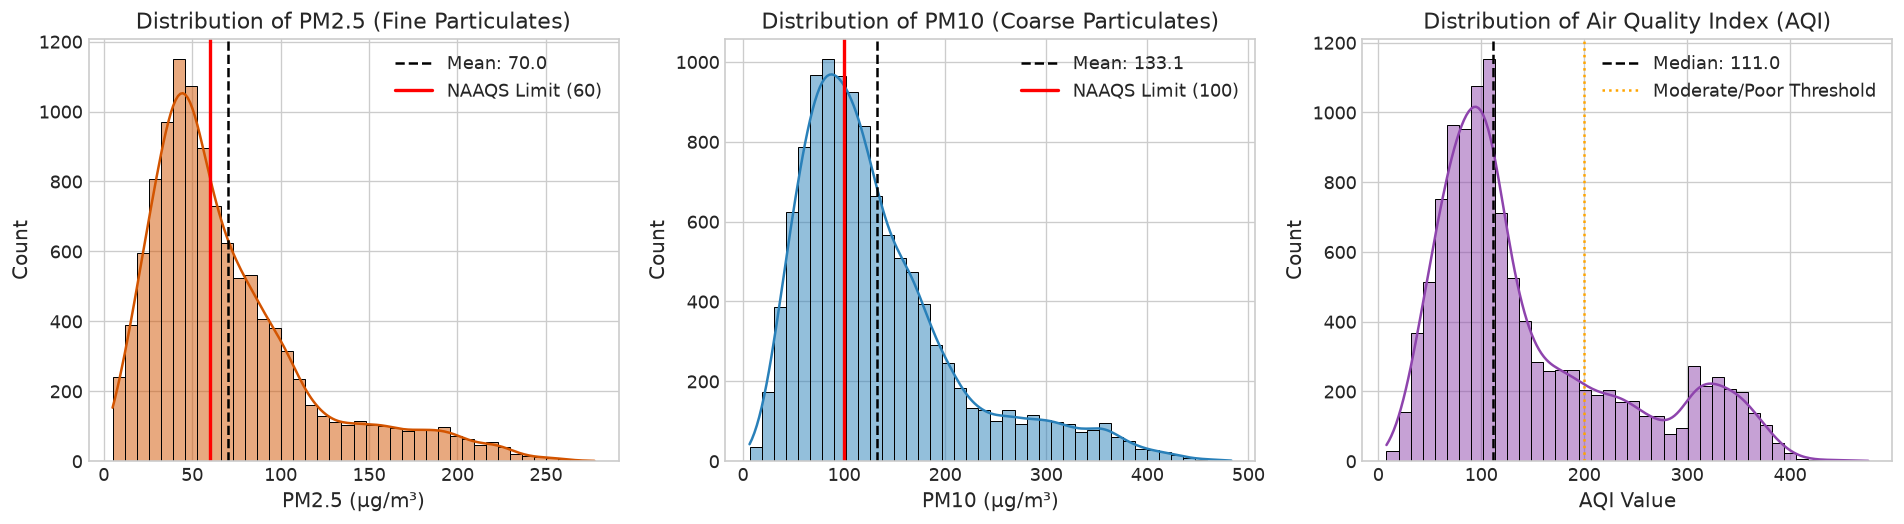

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# PM2.5 Distribution
sns.histplot(df_clean['PM2.5'], kde=True, ax=axes[0], color='#d35400', bins=40)
axes[0].axvline(df_clean['PM2.5'].mean(), color='black', linestyle='--', label=f"Mean: {df_clean['PM2.5'].mean():.1f}")
axes[0].axvline(60, color='red', linestyle='-', linewidth=2, label='NAAQS Limit (60)')
axes[0].set_title('Distribution of PM2.5 (Fine Particulates)')
axes[0].set_xlabel('PM2.5 (µg/m³)')
axes[0].legend()

# PM10 Distribution
sns.histplot(df_clean['PM10'], kde=True, ax=axes[1], color='#2980b9', bins=40)
axes[1].axvline(df_clean['PM10'].mean(), color='black', linestyle='--', label=f"Mean: {df_clean['PM10'].mean():.1f}")
axes[1].axvline(100, color='red', linestyle='-', linewidth=2, label='NAAQS Limit (100)')
axes[1].set_title('Distribution of PM10 (Coarse Particulates)')
axes[1].set_xlabel('PM10 (µg/m³)')
axes[1].legend()

# AQI Distribution
sns.histplot(df_clean['AQI'], kde=True, ax=axes[2], color='#8e44ad', bins=40)
axes[2].axvline(df_clean['AQI'].median(), color='black', linestyle='--', label=f"Median: {df_clean['AQI'].median():.1f}")
axes[2].axvline(200, color='orange', linestyle=':', label='Moderate/Poor Threshold')
axes[2].set_title('Distribution of Air Quality Index (AQI)')
axes[2].set_xlabel('AQI Value')
axes[2].legend()

plt.tight_layout()
plt.show()


---
## 7. Multivariate Correlation Analysis & Atmospheric Interactions
We examine collinearity and interactions between criteria gases and particulates.


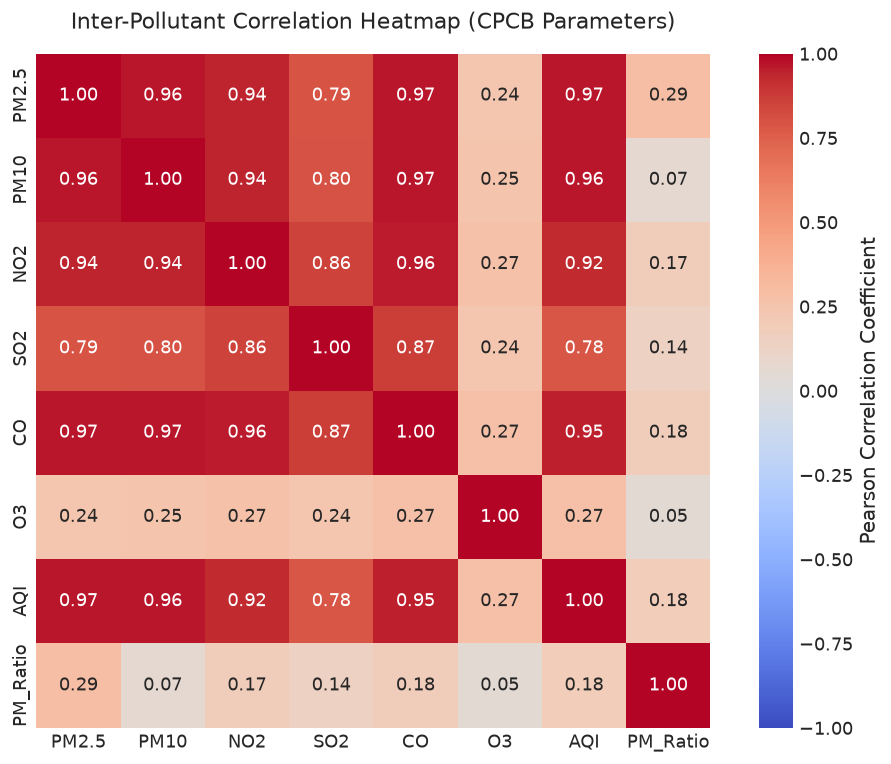

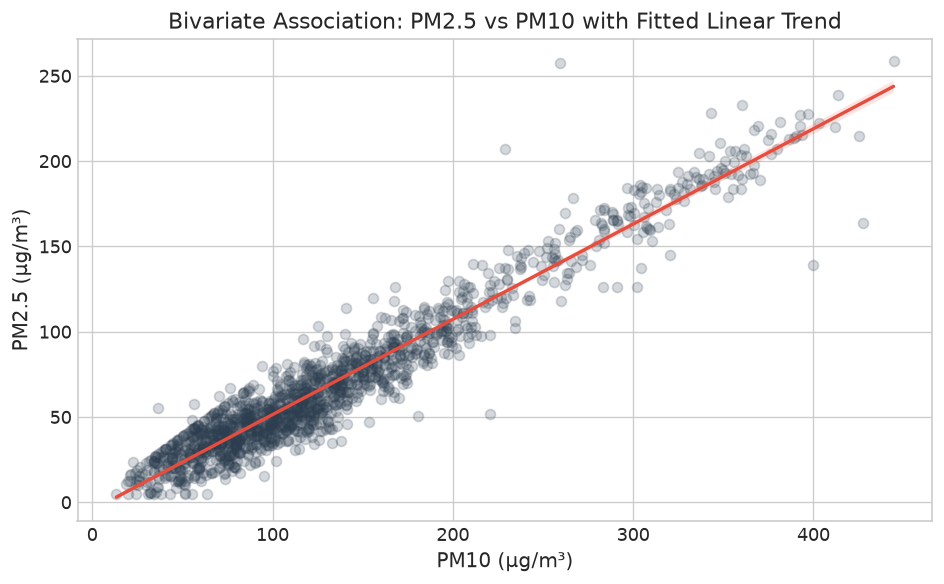

In [7]:
plt.figure(figsize=(8.5, 6.5))
corr_matrix = df_clean[numeric_pollutants + ['AQI', 'PM_Ratio']].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            cbar_kws={'label': 'Pearson Correlation Coefficient'}, square=True)
plt.title('Inter-Pollutant Correlation Heatmap (CPCB Parameters)', pad=15)
plt.tight_layout()
plt.show()

# PM2.5 vs PM10 Linear Relationship
plt.figure(figsize=(8, 5))
sns.regplot(data=df_clean.sample(1500, random_state=42), x='PM10', y='PM2.5', 
            scatter_kws={'alpha':0.2, 'color':'#2c3e50'}, line_kws={'color':'#e74c3c', 'linewidth':2})
plt.title('Bivariate Association: PM2.5 vs PM10 with Fitted Linear Trend')
plt.xlabel('PM10 (µg/m³)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()


---
## 8. Geospatial Disparities: Indo-Gangetic Plain vs. Coastal Peninsular Cities
A crucial hypothesis in Indian air quality studies is that landlocked cities in the Indo-Gangetic Basin suffer significantly higher pollutant accumulation due to the Himalayan meteorological barrier, low wind speeds, and alluvial dust, while coastal cities benefit from maritime breeze dispersion.


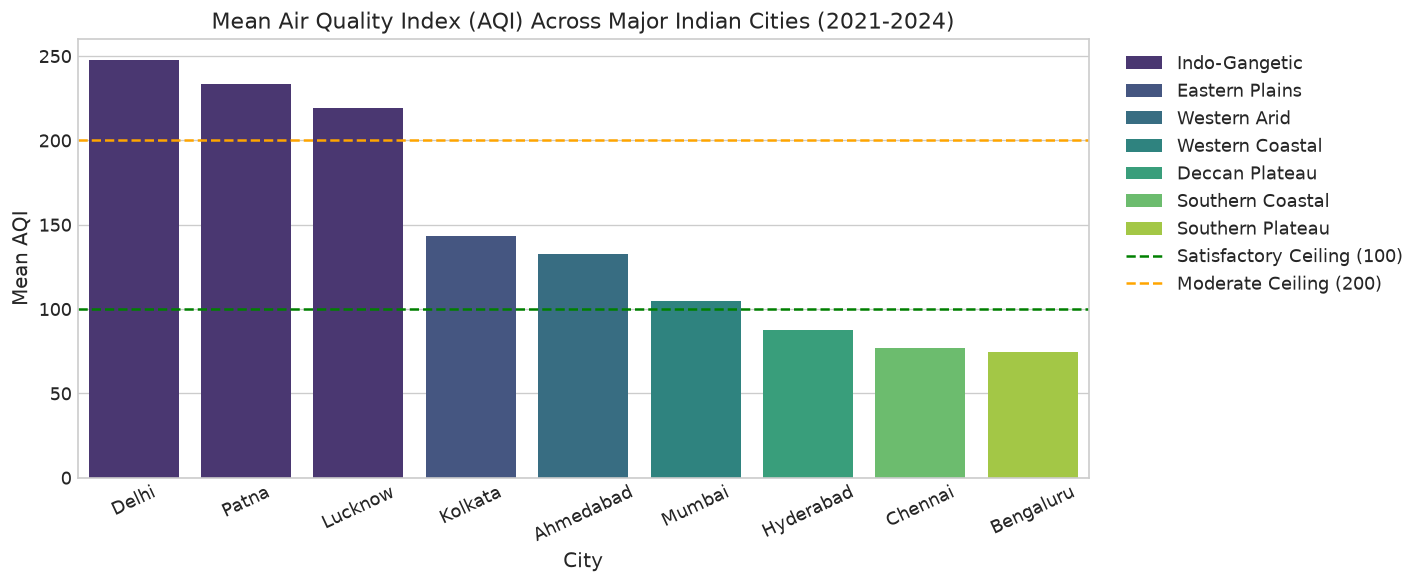

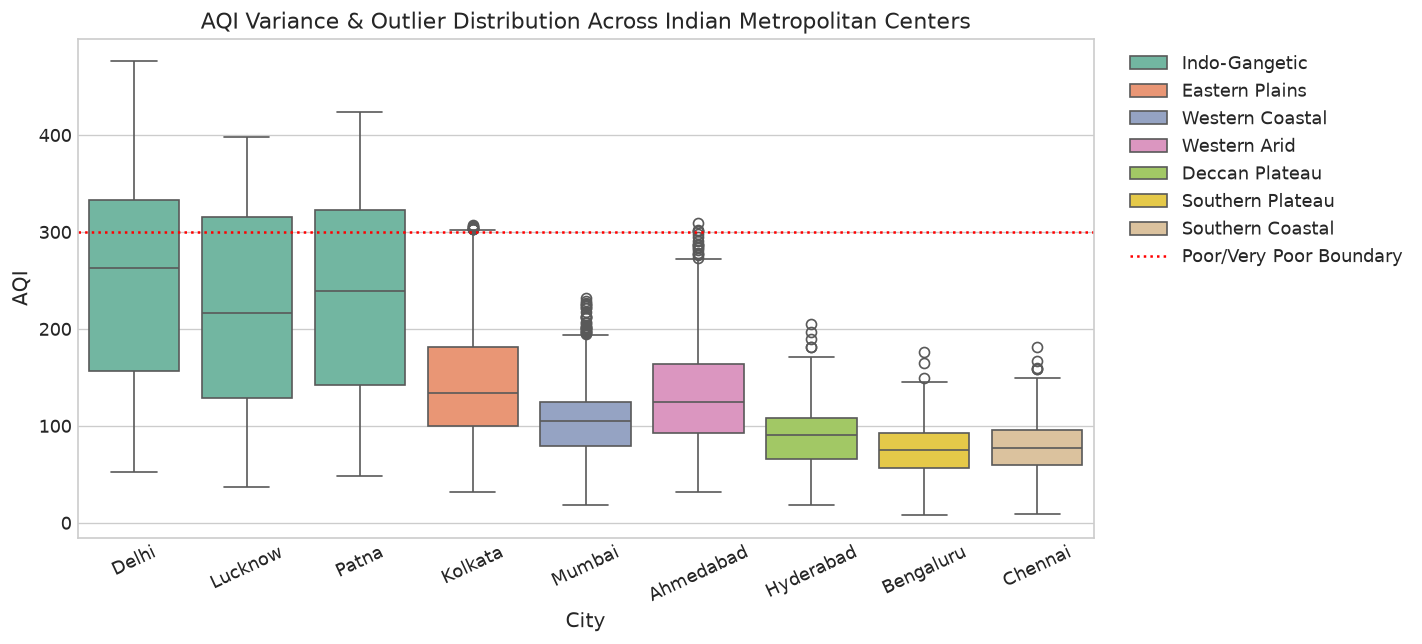

In [8]:
# City-level aggregation
city_summary = df_clean.groupby(['City', 'Zone'])['AQI'].agg(['mean', 'median', 'std', 'max']).reset_index()
city_summary = city_summary.sort_values(by='mean', ascending=False)

plt.figure(figsize=(12, 5))
barplot = sns.barplot(data=city_summary, x='City', y='mean', hue='Zone', dodge=False, palette='viridis')
plt.title('Mean Air Quality Index (AQI) Across Major Indian Cities (2021-2024)')
plt.xlabel('City')
plt.ylabel('Mean AQI')
plt.xticks(rotation=25)
plt.axhline(100, color='green', linestyle='--', label='Satisfactory Ceiling (100)')
plt.axhline(200, color='orange', linestyle='--', label='Moderate Ceiling (200)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Boxplot highlighting regional distributions
plt.figure(figsize=(12, 5.5))
sns.boxplot(data=df_clean, x='City', y='AQI', hue='Zone', palette='Set2')
plt.title('AQI Variance & Outlier Distribution Across Indian Metropolitan Centers')
plt.xticks(rotation=25)
plt.axhline(300, color='red', linestyle=':', label='Poor/Very Poor Boundary')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


---
## 9. Longitudinal Seasonality & Meteorological Inversion
We analyze the monthly progression to identify the winter peak (thermal inversion + biomass burning) versus the monsoon clean air window (wet deposition).


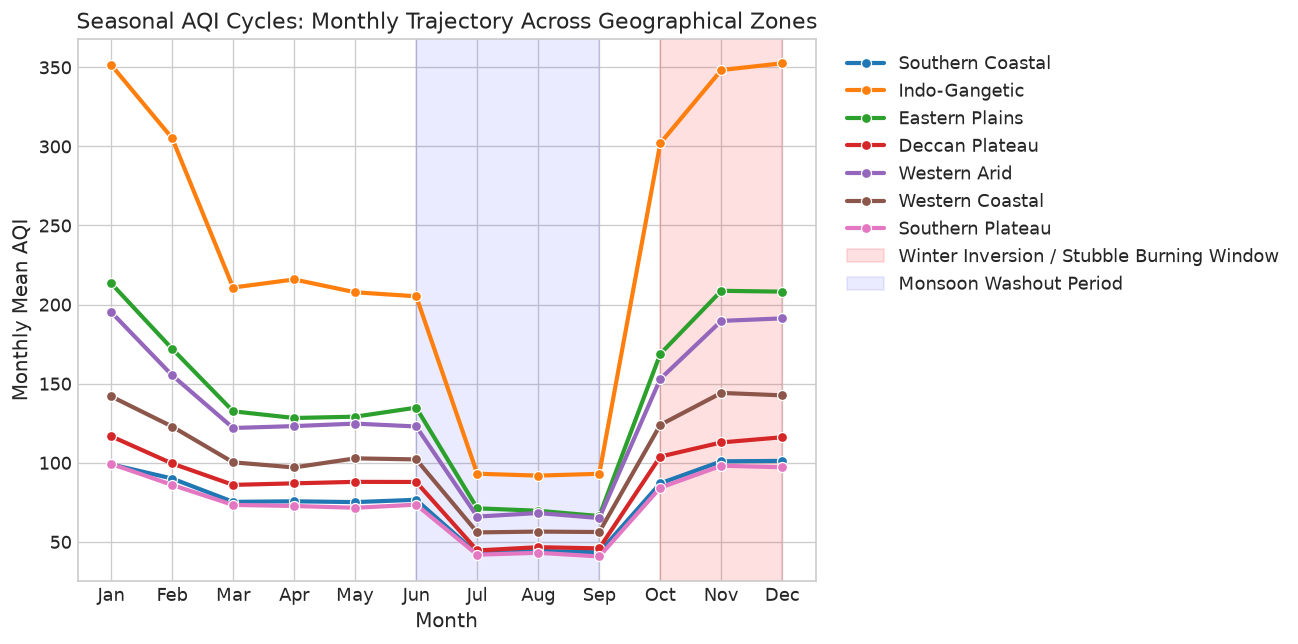

In [9]:
# Aggregate monthly average AQI by Zone
monthly_zone = df_clean.groupby(['Month_Name', 'Month', 'Zone'])['AQI'].mean().reset_index()
monthly_zone = monthly_zone.sort_values(by=['Month'])

plt.figure(figsize=(11, 5.5))
sns.lineplot(data=monthly_zone, x='Month_Name', y='AQI', hue='Zone', marker='o', linewidth=2.5, palette='tab10')
plt.title('Seasonal AQI Cycles: Monthly Trajectory Across Geographical Zones')
plt.xlabel('Month')
plt.ylabel('Monthly Mean AQI')
plt.axvspan(9, 11, color='red', alpha=0.12, label='Winter Inversion / Stubble Burning Window')
plt.axvspan(5, 8, color='blue', alpha=0.08, label='Monsoon Washout Period')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


---
## 10. Epidemiological Exposure: CPCB AQI Bucket Stratification
Under CPCB health guidance:
* **Good / Satisfactory (0-100):** Minimal / minor breathing discomfort to sensitive people.
* **Moderate (101-200):** Breathing discomfort to people with lungs, asthma, and heart diseases.
* **Poor / Very Poor (201-400):** Breathing discomfort to most people on prolonged exposure.
* **Severe (401-500):** Affects healthy people and seriously impacts those with existing diseases.


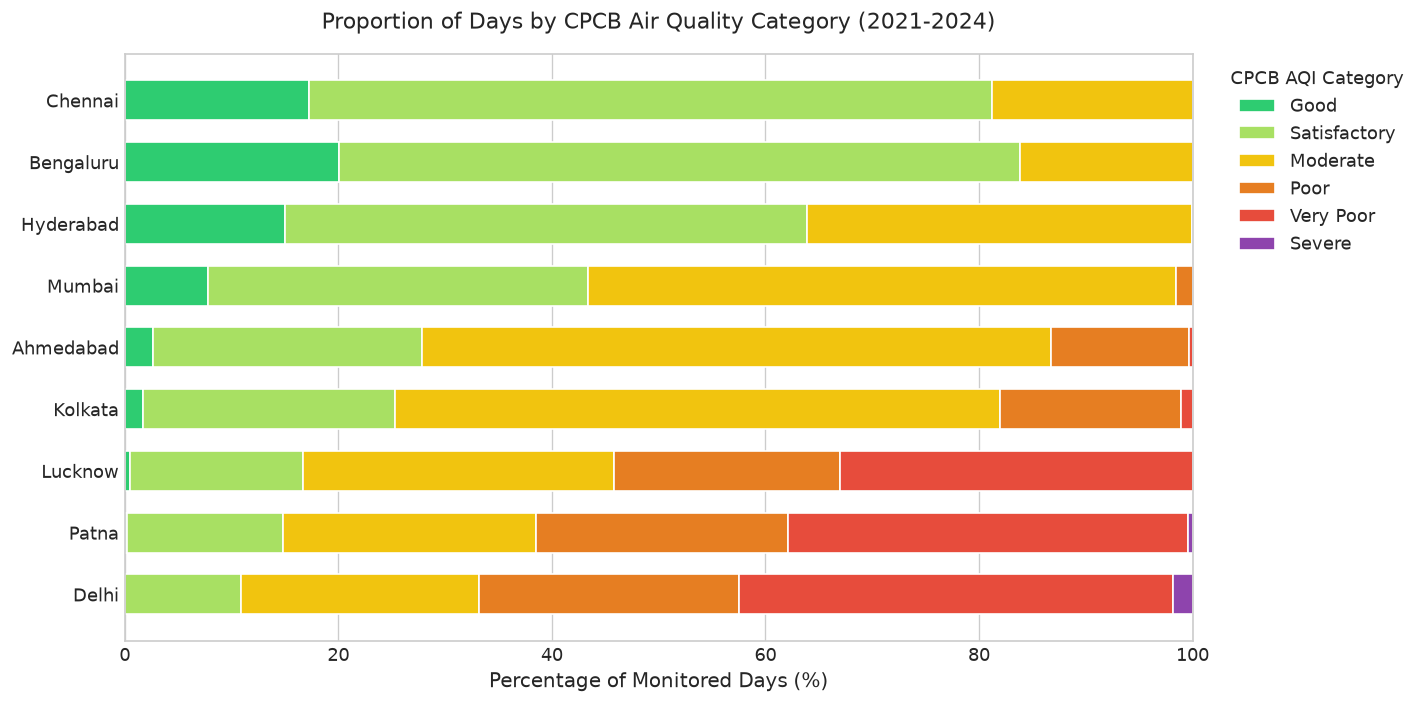

In [10]:
# Calculate percentage of days in each bucket per city
bucket_counts = pd.crosstab(df_clean['City'], df_clean['AQI_Bucket'], normalize='index') * 100
bucket_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
bucket_counts = bucket_counts.reindex(columns=[b for b in bucket_order if b in bucket_counts.columns])

# Sort cities by worst air (percentage of Poor + Very Poor + Severe)
bad_air_sum = bucket_counts.get('Poor', 0) + bucket_counts.get('Very Poor', 0) + bucket_counts.get('Severe', 0)
bucket_counts = bucket_counts.loc[bad_air_sum.sort_values(ascending=False).index]

# Stacked Horizontal Bar Chart
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(bucket_counts))

for bucket in bucket_counts.columns:
    color = AQI_COLORS.get(bucket, '#95a5a6')
    values = bucket_counts[bucket].values
    ax.barh(bucket_counts.index, values, left=bottom, label=bucket, color=color, edgecolor='white', height=0.65)
    bottom += values

ax.set_title('Proportion of Days by CPCB Air Quality Category (2021-2024)', pad=15)
ax.set_xlabel('Percentage of Monitored Days (%)')
ax.set_xlim(0, 100)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='CPCB AQI Category')
plt.tight_layout()
plt.show()


---
## 11. Core Findings & Actionable Policy Insights

### 🔍 Key Analytical Conclusions:
1. **The Indo-Gangetic Plain Geography Penalty:**
   * **Delhi, Patna, and Lucknow** consistently rank in the top quartile of adverse AQI (averaging $> 220$ AQI), spending over **$55\%$ of annual days** in *Poor*, *Very Poor*, or *Severe* categories.
   * In contrast, **Bengaluru, Chennai, and Mumbai** maintain significantly healthier annual distributions (averaging $\le 110$ AQI), demonstrating the profound dispersion effect of maritime breezes and elevation.

2. **Fine-Particle Dominance ($PM_{2.5} / PM_{10}$ Ratio):**
   * The median $PM_{2.5} / PM_{10}$ ratio across northern cities is approximately **$0.55 - 0.65$** during winter months.
   * This elevated ratio mathematically indicates that pollution is not merely ambient dust/crustal matter, but rather **fine combustion aerosols** generated by vehicular tailpipes, industrial emissions, and post-harvest biomass burning.

3. **Predictable Winter Inversion Windows:**
   * Peak toxicity occurs between **November and January**, where temperature inversions trap surface-level pollutants in a shallow boundary layer.
   * The **Monsoon season (July to September)** acts as a natural environmental cleanser, reducing AQI values across all cities by up to **$65\%$** through wet deposition.

---

### 🏛️ Policy & Environmental Interventions (NCAP Roadmap):
* **Source-Apportionment Targeted Action:** Northern regional administrations must focus interventions on fine combustion reduction (EV fleet electrification, bio-decomposer subsidies for crop stubble) rather than generic water misting.
* **Airshed-Level Governance:** Air pollution does not respect state borders. An integrated **Indo-Gangetic Airshed Council** is required to coordinate interstate emission caps across Punjab, Haryana, Delhi, and UP.
* **Early-Warning Algorithmic Deployment:** Deploying 72-hour predictive ML models on meteorological forecasts can allow municipalities to implement graded response action plans (GRAP) proactively rather than reactively.
